
| Problema | Técnica | Matlab |
|-|-|-|
| Respuesta no lineal | Corrección gamma | imadjust(I,[],[],g) |
| Luz desigual | Dividir por el fondo | I./imclose(I,se) |
| Rango estrecho | Estiramiento por percentiles | imadjust(I,stretchlim(I)) |
| Rango dinámico enorme | Logaritmo | log(1+I) |
| Contraste global bajo | Ecualización | histeq, adapthisteq |
| Detectar cambios | Resta y máscara | imabsdiff, &, \| |
| Bordes suaves | Restar el laplaciano | imfilter + resta |

In [2]:
import kagglehub

# kagglehub.login()

In [3]:
dataset = "soumikrakshit/dark-face-dataset"

image_indexes = [206, 1700, 2511, 3034]

images = [f"image/{index}.png" for index in image_indexes]

paths = []

for image in images:
    path = kagglehub.dataset_download(dataset, path=image)
    paths.append(path)

for path in paths:
    print(path)

C:\Users\Usuario\.cache\kagglehub\datasets\soumikrakshit\dark-face-dataset\versions\1\image/206.png
C:\Users\Usuario\.cache\kagglehub\datasets\soumikrakshit\dark-face-dataset\versions\1\image/1700.png
C:\Users\Usuario\.cache\kagglehub\datasets\soumikrakshit\dark-face-dataset\versions\1\image/2511.png
C:\Users\Usuario\.cache\kagglehub\datasets\soumikrakshit\dark-face-dataset\versions\1\image/3034.png


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from abc import ABC, abstractmethod

In [5]:
class Image(ABC):
    def __init__(self, path, clipLimit=2.0, tileGridSize=(8, 8)):
        self.img = cv2.imread(path)
        self.clahe = cv2.createCLAHE(clipLimit=clipLimit, tileGridSize=tileGridSize)

    @abstractmethod
    def _get_target(self):
        pass

    @abstractmethod
    def _set_target(self, target):
        pass

    @abstractmethod
    def hist(self):
        return self

    @abstractmethod
    def show(self):
        return self

    def print_specs(self):
        print(f"Dimensiones (Alto, Ancho, Canales): {self.img.shape}")
        print(f"Tipo de dato: {self.img.dtype}")

    def lineal_correction(self, alpha=1.0, beta=0.0):
        """
        Manual lineal correction
        """
        corrected = alpha * self._get_target().astype(np.float32) + beta
        self._set_target(np.clip(corrected, 0, 255).astype(np.uint8))

        return self

    def contrast_stretch(self, alpha=0, beta=255):
        """Aplica un estiramiento de contraste lineal robusto con NORM_MINMAX"""
        target = np.asarray(self._get_target()).astype(np.float32)

        normalized = np.empty_like(target)

        cv2.normalize(
            src=target,
            dst=normalized,
            alpha=alpha,
            beta=beta,
            norm_type=cv2.NORM_MINMAX
        )

        self._set_target(np.clip(normalized, 0, 255).astype(np.uint8))
        return self

    def adjust_gamma(self, c=1.0, gamma=1 / 2.2):
        """
        Fix non-linear response
        """
        img_norm = self._get_target().astype(np.float32) / 255.0
        img_gamma = c * np.power(img_norm, gamma)
        self._set_target((img_gamma * 255).astype(np.uint8))

        return self

    def set_clahe(self, clipLimit=None, tileGridSize=None):
        """
        Changes clahe clipLimit and tileGridSize
        """
        if clipLimit is not None:
            self.clahe.setClipLimit(clipLimit)

        if tileGridSize is not None:
            self.clahe.setTilesGridSize(tileGridSize)

    def apply_clahe(self):
        """
        Applies CLAHE to the image
        """
        target = np.asarray(self._get_target())
        processed = self.clahe.apply(target)
        self._set_target(processed)

        return self

    def piecewise(self, x: list[int], y: list[int]):
        """
        Applies piecewise linear contrast stretching
        """
        img_piecewise = np.interp(self._get_target().ravel(), x, y).reshape(
            self._get_target().shape
        )

        self._set_target(np.clip(img_piecewise, 0, 255).astype(np.uint8))

        return self

    def percentile_stretching(self, lp=2.0, hp=98.0):
        """
        Applies contrast stretching based on image percentiles
        """
        target = np.asarray(self._get_target())

        p_low, p_high = np.percentile(target, [lp, hp])

        if p_low == p_high:
            return self

        stretched = (target.astype(np.float32) - p_low) * 255.0 / (p_high - p_low)
        self._set_target(np.clip(stretched, 0, 255).astype(np.uint8))

        return self

    def log_transform(self):
        """
        Applies logaritmic transform to the image
        """
        target = np.asarray(self._get_target()).astype(np.float32)

        c = 255.0 / np.log(1.0 + 255.0)

        transformed = c * np.log(1.0 + target)
        self._set_target(np.clip(transformed, 0, 255).astype(np.uint8))

        return self

    def non_lineal_stretch(self, k=None, e=1.0):
        """
        Applies non lineal stretch
        """
        target = np.asarray(self._get_target()).astype(np.float32)

        target = np.clip(target, 1e-5, 255.0)

        if k is None:
            k = np.median(target)

        stretched = 255.0 / (1 + np.power(k / target, e))
        self._set_target(np.clip(stretched, 0, 255).astype(np.uint8))

        return self

    def negative(self):
        target = np.asarray(self._get_target())

        self._set_target(255 - target)

        return self

    def realce_borders(self, k_size=(5, 5), sigma=0, alpha=1.5, debug=False):
        target = np.asarray(self._get_target()).astype(np.float32)

        softened = cv2.GaussianBlur(target, k_size, sigma)
        details = target - softened
        realced_img = target + alpha * details

        if debug:
            fig, axes = plt.subplots(1, 4, figsize=(16, 4))

            axes[0].imshow(target, cmap='gray', vmin=0, vmax=255)
            axes[0].set_title("1. Original")
            axes[0].axis('off')

            axes[1].imshow(softened, cmap='gray', vmin=0, vmax=255)
            axes[1].set_title("2. Softened")
            axes[1].axis('off')

            axes[2].imshow(details, cmap='gray')
            axes[2].set_title("3. Details")
            axes[2].axis('off')

            axes[3].imshow(np.clip(realced_img, 0, 255), cmap='gray', vmin=0, vmax=255)
            axes[3].set_title(f"4. Realced (α={alpha})")
            axes[3].axis('off')

            plt.tight_layout()
            plt.show()

        self._set_target(np.clip(realced_img, 0, 255).astype(np.uint8))

        return self

    def print_stats(self):
        target = self._get_target()
        print(f"Media: {np.mean(target)}")
        print(f"p25: {np.percentile(target, 25)}")
        print(f"Mediana: {np.median(target)}")
        print(f"p75: {np.percentile(target, 75)}")
        print(f"p95: {np.percentile(target, 95)}")



In [6]:
class GrayImage(Image):
    def __init__(self, path, clipLimit=2.0, tileGridSize=(8, 8)):
        super().__init__(path, clipLimit=clipLimit, tileGridSize=tileGridSize)
        self.img = cv2.cvtColor(self.img, cv2.COLOR_BGR2GRAY)

    def _get_target(self):
        return self.img

    def _set_target(self, target):
        self.img = target

    def show(self, ax=None):
        if ax is None:
            fig, ax = plt.subplots(figsize=(12, 8))
            ax.imshow(self.img, cmap="gray")
            ax.axis("off")
            plt.show()
        else:
            ax.imshow(self.img, cmap="gray")
            ax.axis("off")

        return self

    def hist(self, ax=None):
        if ax is None:
            fig, ax = plt.subplots()
            ax.hist(self.img.ravel(), bins=256, range=(0, 256), color="gray")
            plt.show()
        else:
            ax.hist(self.img.ravel(), bins=256, range=(0, 256), color="gray")

        return self

In [7]:
class LABImage(Image):
    def __init__(self, path, clipLimit=2.0, tileGridSize=(8, 8)):
        super().__init__(path, clipLimit=clipLimit, tileGridSize=tileGridSize)
        self.img = cv2.cvtColor(self.img, cv2.COLOR_BGR2LAB)

    def _get_target(self):
        return self.img[:, :, 0]

    def _set_target(self, target):
        self.img[:, :, 0] = target

    def show(self, ax=None):
        rgb_img = cv2.cvtColor(self.img, cv2.COLOR_LAB2RGB)

        if ax is None:
            fig, ax = plt.subplots(figsize=(12, 8))
            ax.imshow(rgb_img)
            ax.axis("off")
            plt.show()
        else:
            ax.imshow(rgb_img)
            ax.axis("off")

        return self

    def hist(self, ax=None):
        l_channel = self.img[:, :, 0]

        if ax is None:
            fig, ax = plt.subplots()
            ax.hist(l_channel.ravel(), bins=256, range=(0, 256), color="gray")
            plt.show()
        else:
            ax.hist(l_channel.ravel(), bins=256, range=(0, 256), color="gray")

        return self

In [8]:
def show_image_and_hist(img):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    img.show(ax=axes[0])
    axes[0].set_title("Imagen")

    img.hist(ax=axes[1])
    axes[1].set_title("Histograma")

    plt.tight_layout()
    plt.show()


def print_pipeline(img, operations):
    show_image_and_hist(img)
    for op in operations:
        op(img)
        show_image_and_hist(img)

Dimensiones (Alto, Ancho, Canales): (720, 1080, 3)
Tipo de dato: uint8
Media: 13.216729681069959
p25: 1.0
Mediana: 2.0
p75: 7.0
p95: 82.0


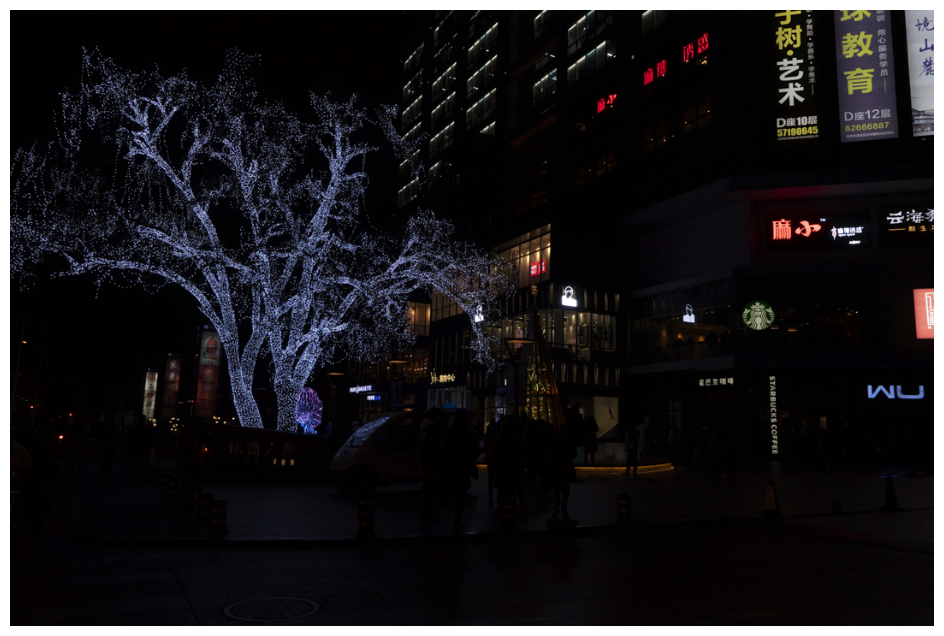

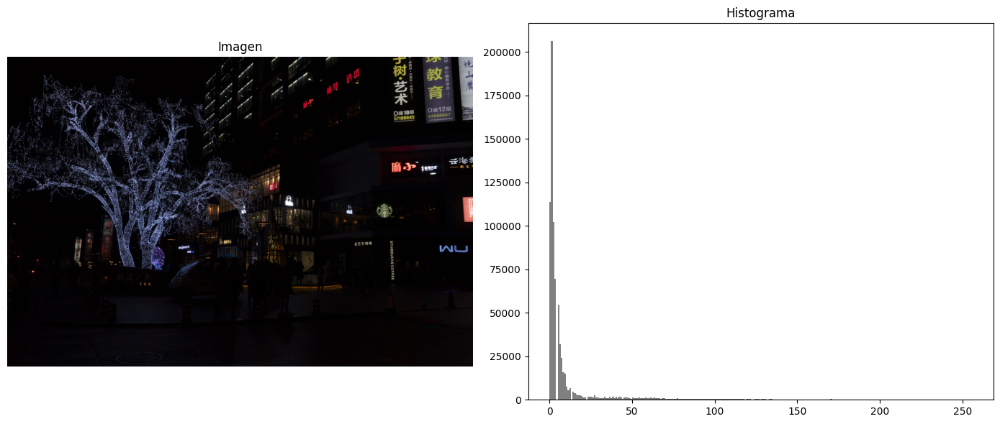

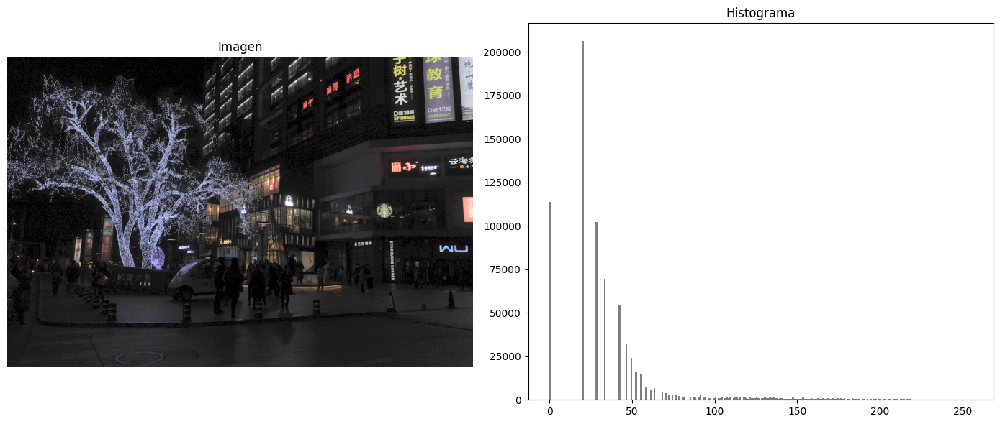

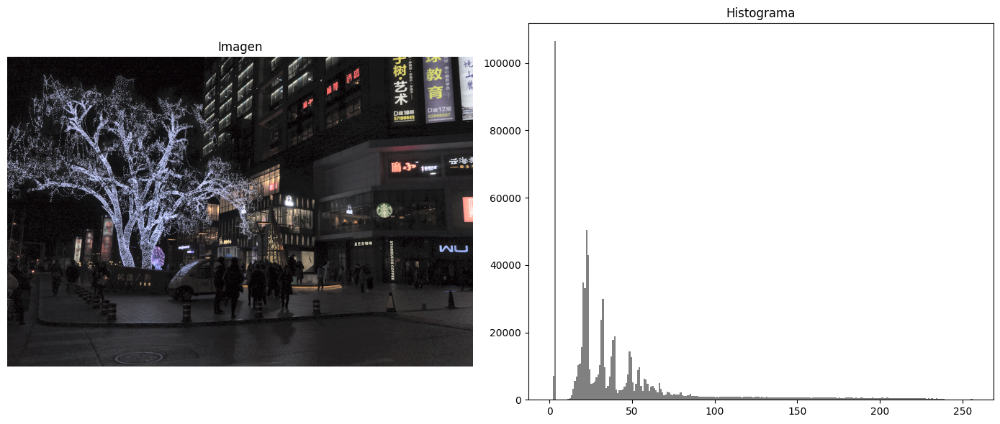

Media: 46.140207047325106
p25: 20.0
Mediana: 31.0
p75: 53.0
p95: 168.0


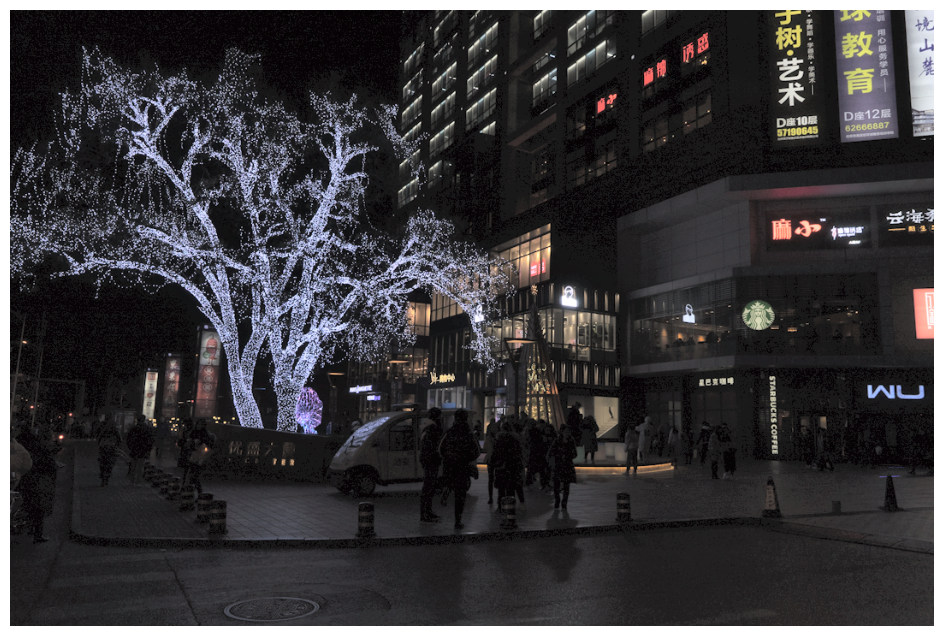

In [9]:
img = LABImage(path=paths[0])
img.print_specs()
img.print_stats()
img.show()

operations = [
    lambda i: i.adjust_gamma(),
    lambda i: i.apply_clahe(),
]

print_pipeline(img, operations)
img.print_stats()
img.show()

Media: 0.26180555555555557
p25: 0.0
Mediana: 0.0
p75: 0.0
p95: 1.0


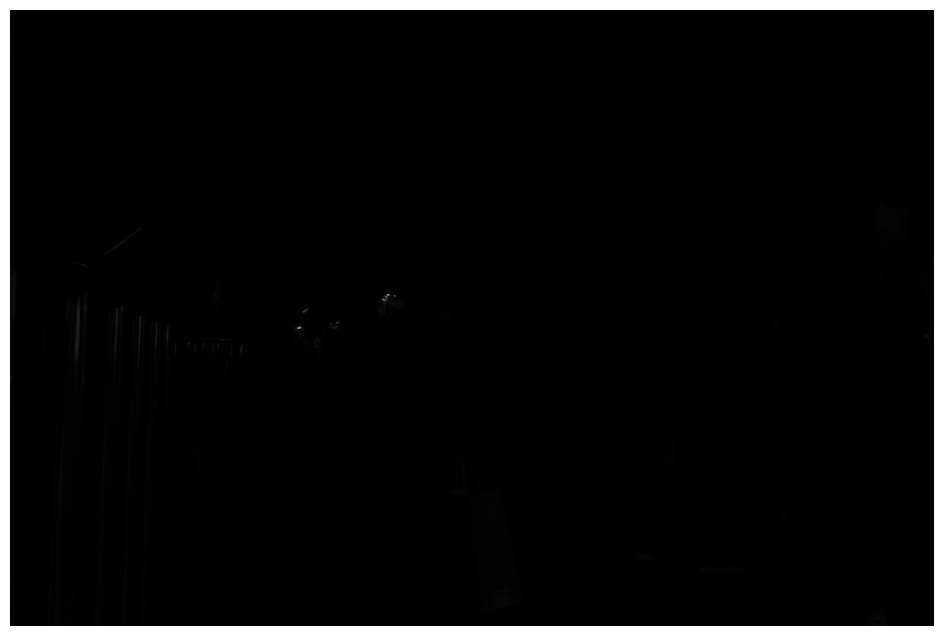

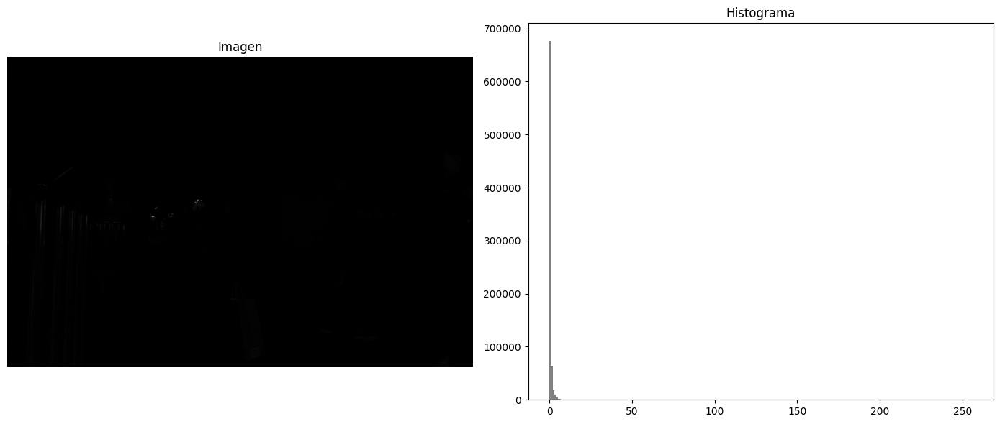

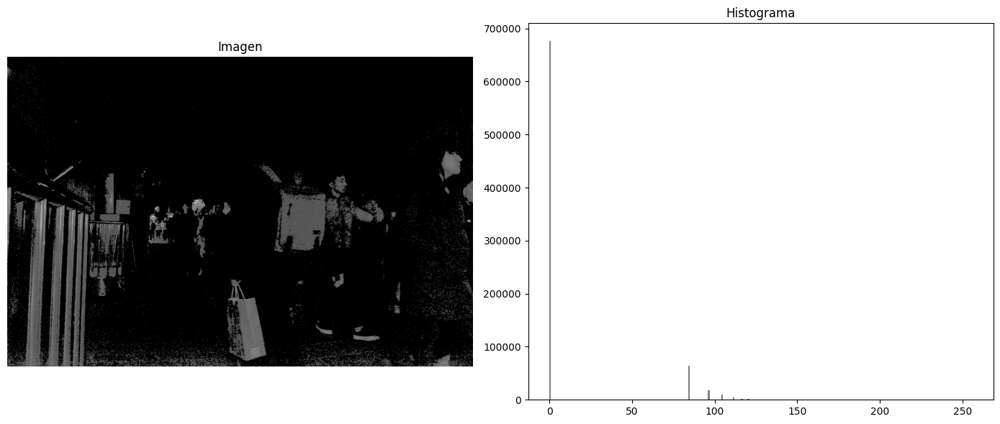

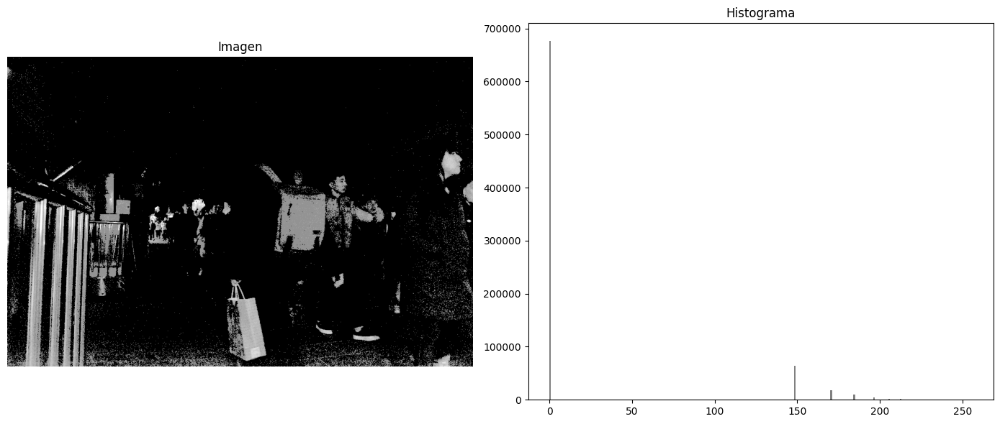

Media: 21.159447016460906
p25: 0.0
Mediana: 0.0
p75: 0.0
p95: 148.0


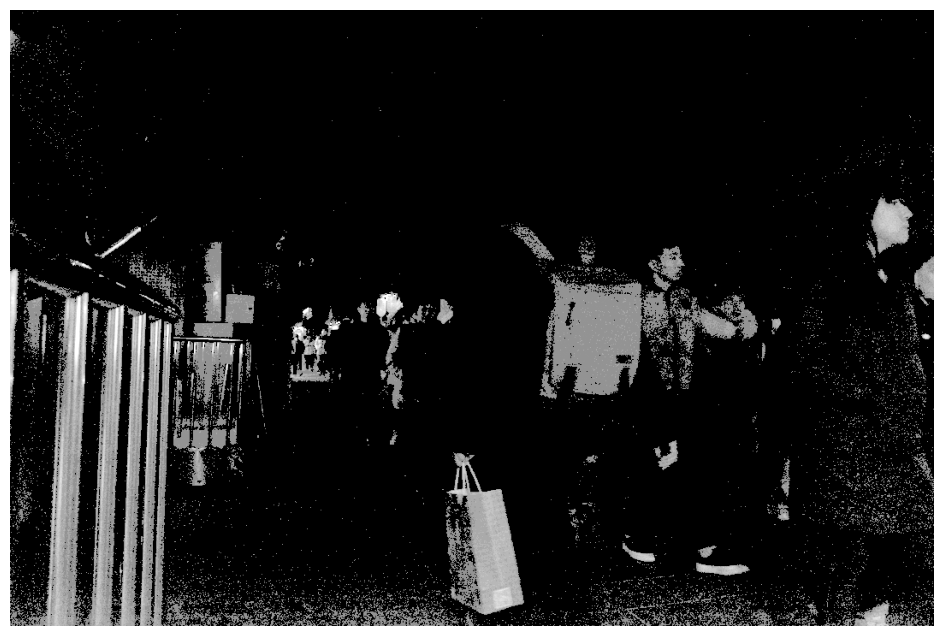

In [10]:
img = GrayImage(path=paths[1])
img.print_stats()
img.show()

operations = [
    lambda i: i.adjust_gamma(gamma=0.2),
    lambda i: i.percentile_stretching(lp=2, hp=99.9)
]

print_pipeline(img, operations)

img.print_stats()
img.show()

Media: 43.58990354938272
p25: 8.0
Mediana: 28.0
p75: 68.0
p95: 137.0


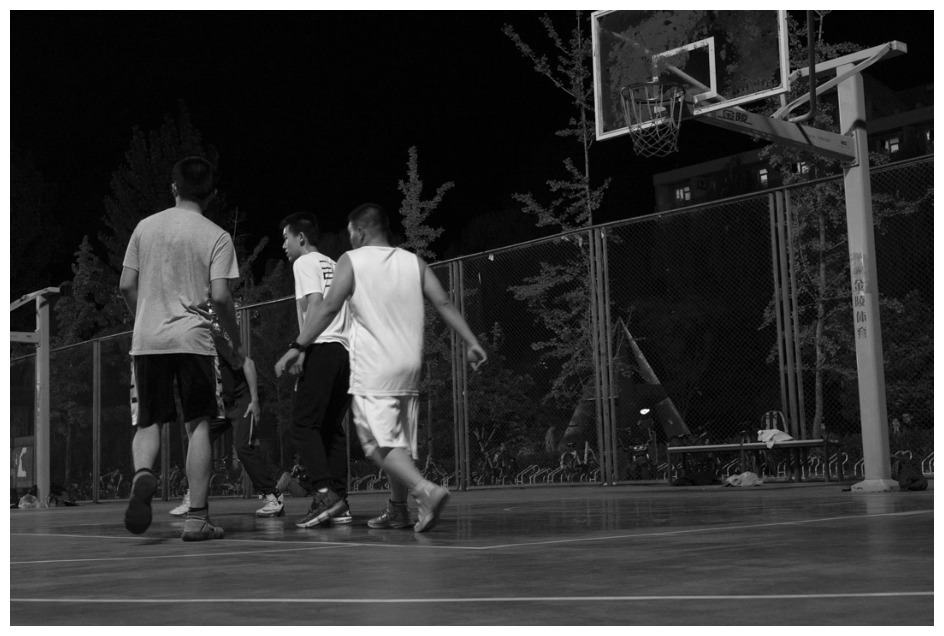

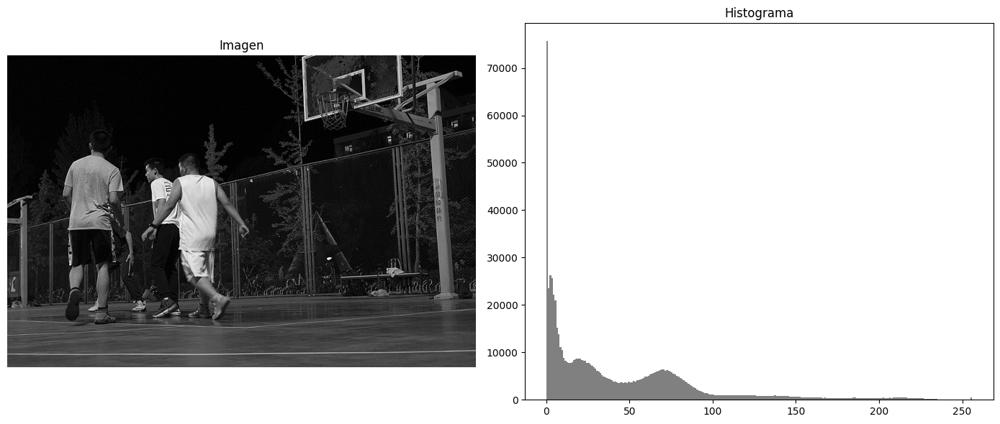

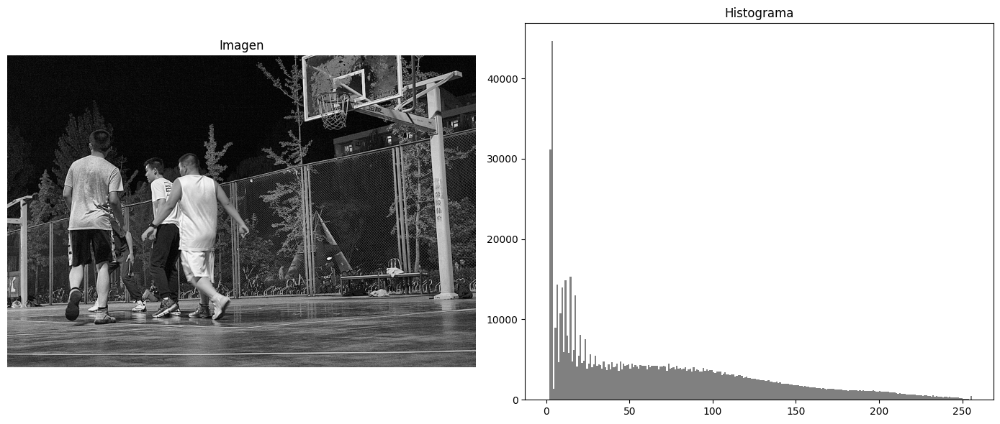

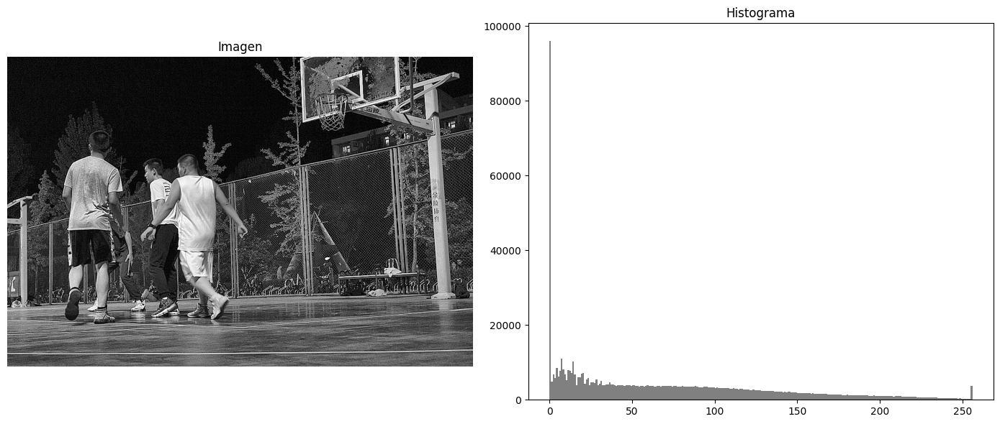

Media: 71.54327546296297
p25: 14.0
Mediana: 57.0
p75: 114.0
p95: 200.0


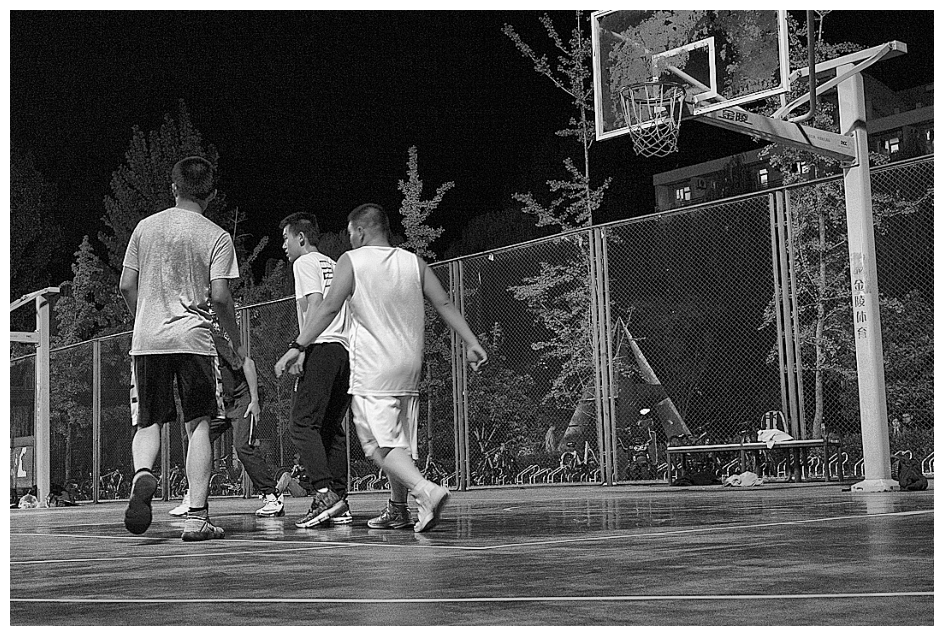

In [11]:
img = GrayImage(path=paths[2])
img.print_stats()
img.show()

operations = [
    lambda i: i.apply_clahe(),
    lambda i: i.realce_borders(alpha=0.5),
]
img.realce_borders()
print_pipeline(img, operations)
img.print_stats()
img.show()


Media: 24.952490997942387
p25: 5.0
Mediana: 16.0
p75: 23.0
p95: 99.0


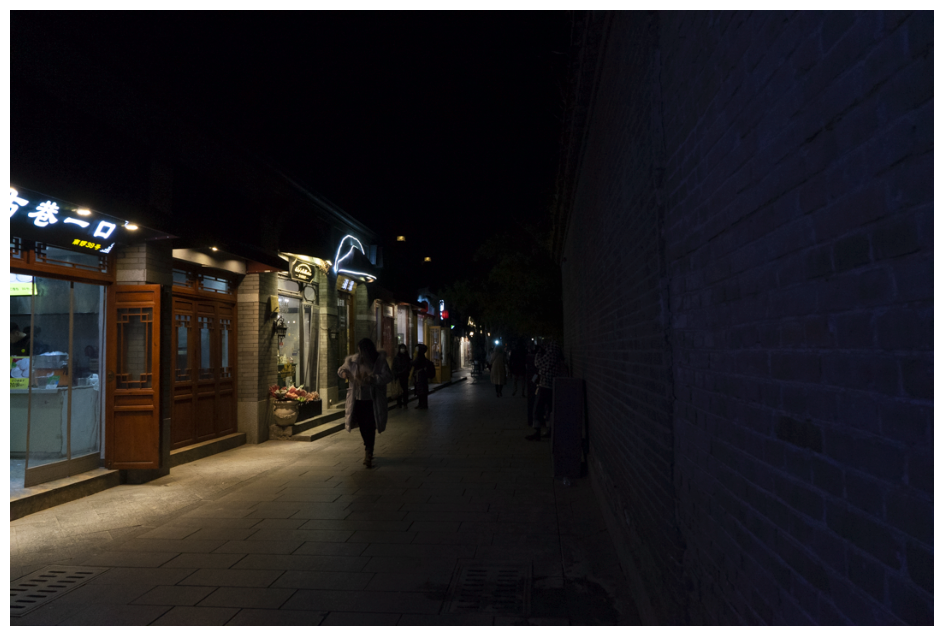

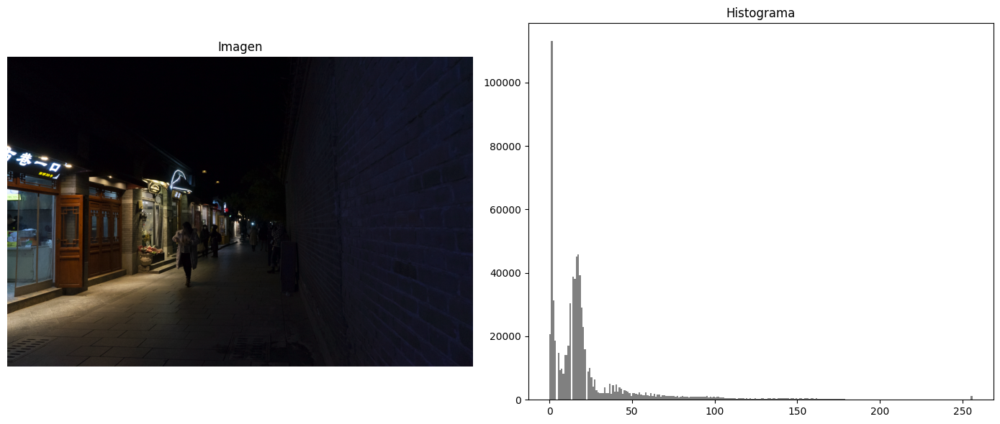

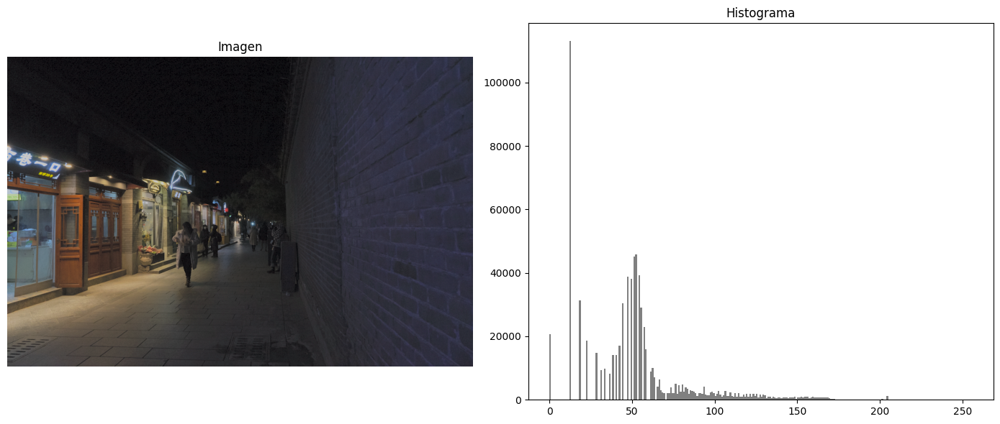

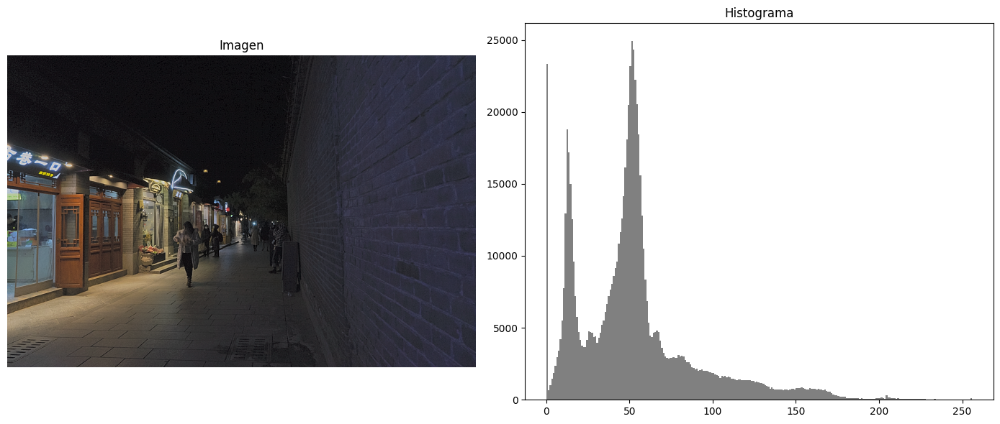

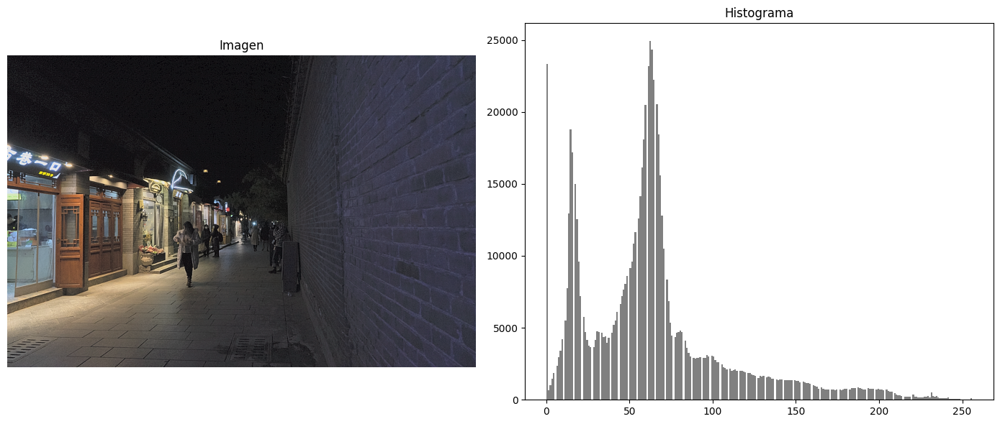

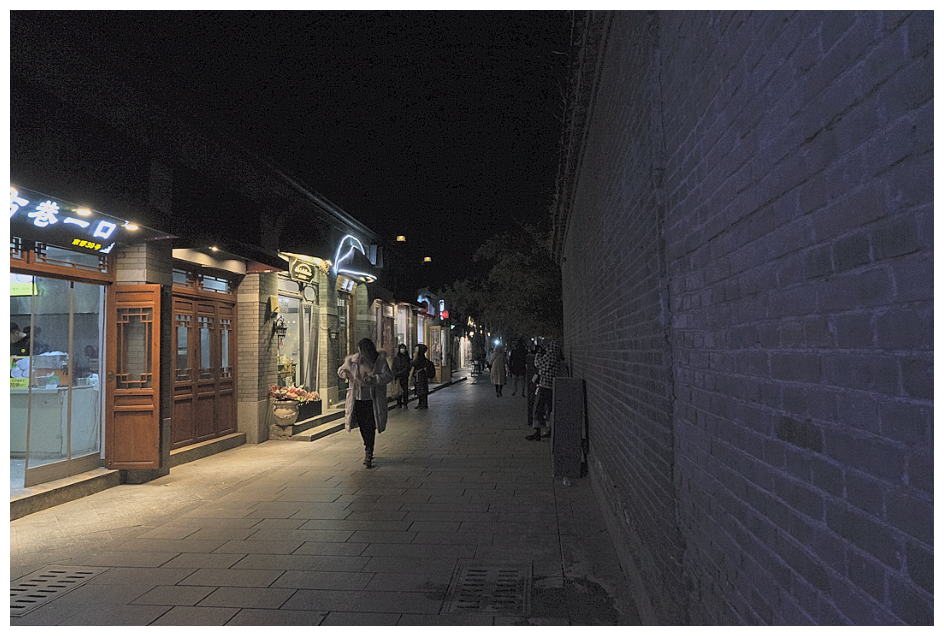

In [12]:
img = LABImage(path=paths[3])
img.print_stats()
img.show()

x = [0,180,255]
y = [0,220,255]

operations = [
    lambda i: i.adjust_gamma(c=0.8, gamma=0.5),
    lambda i: i.realce_borders(alpha=1.5),
    lambda i: i.piecewise(x, y),
]

print_pipeline(img, operations)

img.show()

<>:10: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:10: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
C:\Users\Usuario\AppData\Local\Temp\ipykernel_24468\3819559579.py:10: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
  plt.plot(r, s, label=f'$\gamma = {gamma}$')


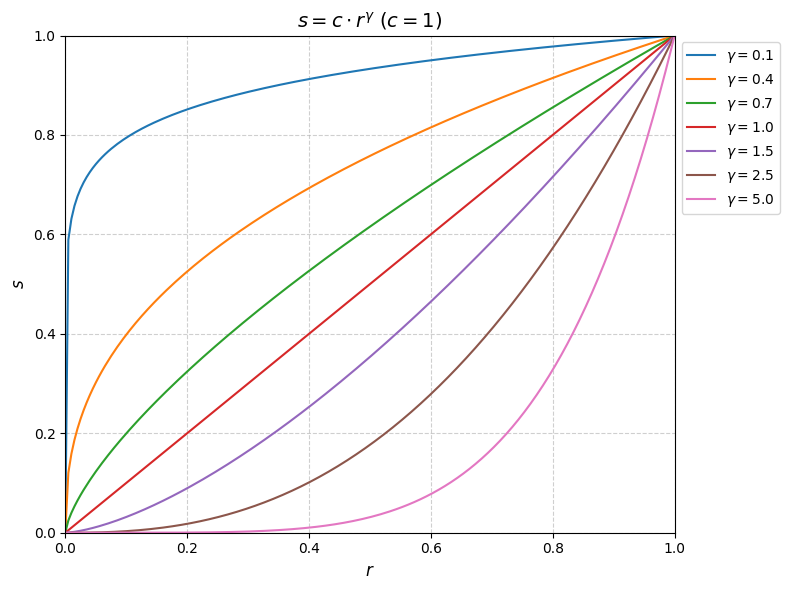

In [13]:
r = np.linspace(0.0, 1.0, 200)
c = 1.0

gammas = [0.1, 0.4, 0.7, 1.0, 1.5, 2.5, 5.0]

plt.figure(figsize=(8, 6))

for gamma in gammas:
    s = c * (r ** gamma)
    plt.plot(r, s, label=f'$\gamma = {gamma}$')

# Configuración del gráfico
plt.title(r'$s = c \cdot r^\gamma$ ($c = 1$)', fontsize=14)
plt.xlabel('$r$', fontsize=12)
plt.ylabel('$s$', fontsize=12)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()